In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt

In [3]:
#Truncation part
def kl_divergence(a, p):
    res = np.log((a/p)**a*((1-a)/(1-p))**(1-a))
    return res

def find_k(t, p, delta):
    k = math.ceil(t*p)
    while k < t:
        kl = kl_divergence((k+1)/t, p)
        if t*kl >= np.log(2/delta):
            break
        else:
            k += 1
    return k

In [4]:
#Low rank part
def final_rank(k, nu, delta):
    if 2**k <= 16*(nu**(-2*k))*(delta**(-2)):
        return 2**k
    else:
        return 16*(nu**(-2*k))*(delta**(-2))

In [5]:
def compute_numbers(memory, each_occupation):
    return memory/each_occupation

In [6]:
MB = compute_numbers(10**6, 8)
GB = compute_numbers(10**9, 8)
TB = compute_numbers(10**12, 8)
PB = compute_numbers(10**15, 8)

# Qubit (Dephasing)

In [7]:
def r(p):
    return 1- (2+np.sqrt(2))*p

nu0 = np.cos(np.pi/8)


<>:69: SyntaxWarning: invalid escape sequence '\d'
<>:69: SyntaxWarning: invalid escape sequence '\d'
C:\Users\hjw4\AppData\Local\Temp\ipykernel_22796\69696324.py:69: SyntaxWarning: invalid escape sequence '\d'
  plt.title('Qubit (Dephasing), $\delta=0.01$', fontsize=23)
C:\Users\hjw4\AppData\Local\Temp\ipykernel_22796\3587647202.py:3: RuntimeWarning: divide by zero encountered in scalar divide
  res = np.log((a/p)**a*((1-a)/(1-p))**(1-a))


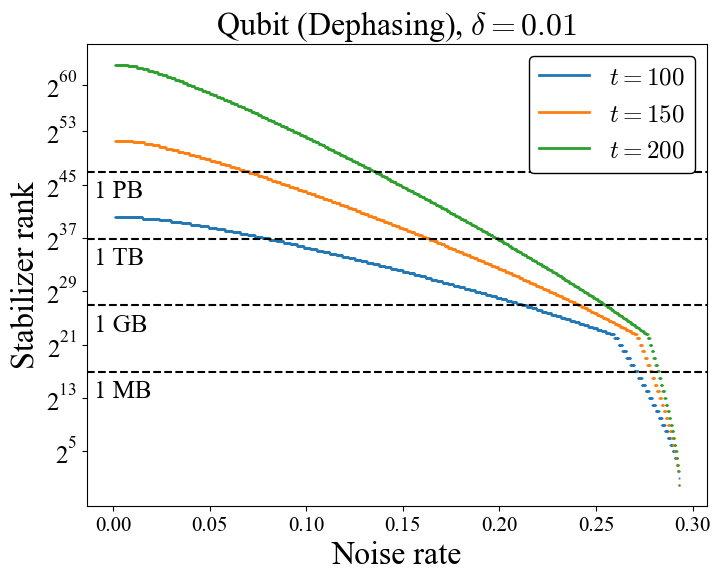

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

delta = 0.01
t1, t2, t3 = 100, 150, 200

p = np.linspace(0.001, (1 - np.tan(np.pi/8)) / 2, 2000)

y1 = []
y2 = []
y3 = []
for i in range(len(p)):
    k1 = find_k(t1, r(p[i]), delta)
    k2 = find_k(t2, r(p[i]), delta)
    k3 = find_k(t3, r(p[i]), delta)
    y1.append(final_rank(k1, nu0, delta))
    y2.append(final_rank(k2, nu0, delta))
    y3.append(final_rank(k3, nu0, delta))


plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']
plt.rcParams['mathtext.fontset'] = 'cm'

plt.figure(figsize=(8, 6))


ln1 = plt.plot(p, y1, linestyle='None', marker='.', markersize=1)[0]
ln2 = plt.plot(p, y2, linestyle='None', marker='.', markersize=1)[0]
ln3 = plt.plot(p, y3, linestyle='None', marker='.', markersize=1)[0]

plt.xlabel('Noise rate', fontsize=23)
plt.ylabel('Stabilizer rank', fontsize=23)
plt.yscale('log', base=2)

plt.axhline(MB, linestyle='--', color='k')
plt.text(-0.01, 2**13, '1 MB', fontsize=18)

plt.axhline(GB, linestyle='--', color='k')
plt.text(-0.01, 2**23, '1 GB', fontsize=18)

plt.axhline(TB, linestyle='--', color='k')
plt.text(-0.01, 2**33, '1 TB', fontsize=18)

plt.axhline(PB, linestyle='--', color='k')
plt.text(-0.01, 2**43, '1 PB', fontsize=18)


colors = [ln1.get_color(), ln2.get_color(), ln3.get_color()]

proxy_handles = [
    Line2D([0], [0], color=colors[0], lw=2),
    Line2D([0], [0], color=colors[1], lw=2),
    Line2D([0], [0], color=colors[2], lw=2),
]
proxy_labels = [r'$t=100$', r'$t=150$', r'$t=200$']

plt.legend(proxy_handles, proxy_labels,
           fontsize=18,
           framealpha=1.0,
           edgecolor='k',
           handlelength=2.0,
           loc='upper right')

plt.xticks(fontsize=15)
plt.yticks([2**5, 2**13, 2**21, 2**29, 2**37, 2**45, 2**53, 2**60], fontsize=18)

plt.title('Qubit (Dephasing), $\delta=0.01$', fontsize=23)
plt.savefig('Qubit(Dephasing)', dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.show()


# Fermion (Particle loss)

In [9]:
def N(p):
    return p**2 + (1-p)**2

def nu1(p):
    res = np.sqrt((2*p**2 - 2*p + 1)/(3*p**2 - 2*p + 1))
    return res

<>:68: SyntaxWarning: invalid escape sequence '\d'
<>:68: SyntaxWarning: invalid escape sequence '\d'
C:\Users\hjw4\AppData\Local\Temp\ipykernel_22796\304504280.py:68: SyntaxWarning: invalid escape sequence '\d'
  plt.title('Fermion (Particle loss), $\delta=0.01$', fontsize=23)


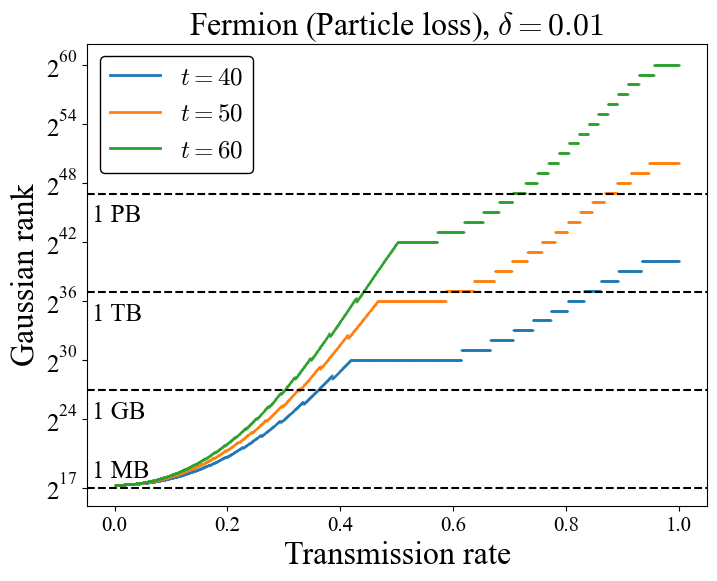

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


delta = 0.01
t1, t2, t3 = 40, 50, 60
p = np.linspace(0.001, 1, 2000)

y1 = []
y2 = []
y3 = []
for i in range(len(p)):
    k1 = find_k(t1, N(p[i]), delta)
    k2 = find_k(t2, N(p[i]), delta)
    k3 = find_k(t3, N(p[i]), delta)
    y1.append(final_rank(k1, nu1(p[i]), delta))
    y2.append(final_rank(k2, nu1(p[i]), delta))
    y3.append(final_rank(k3, nu1(p[i]), delta))


plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']
plt.rcParams['mathtext.fontset'] = 'cm'

plt.figure(figsize=(8,6))

ln1 = plt.plot(p, y1, linestyle='None', marker='.', markersize=1, alpha=0.9)[0]
ln2 = plt.plot(p, y2, linestyle='None', marker='.', markersize=1, alpha=0.9)[0]
ln3 = plt.plot(p, y3, linestyle='None', marker='.', markersize=1, alpha=0.9)[0]

plt.xlabel('Transmission rate', fontsize=23)
plt.ylabel('Gaussian rank', fontsize=23)
plt.yscale('log', base=2)


plt.axhline(MB, linestyle='--', color='k')
plt.text(-0.04, 2**18, '1 MB', fontsize=18)

plt.axhline(GB, linestyle='--', color='k')
plt.text(-0.04, 2**24, '1 GB', fontsize=18)

plt.axhline(TB, linestyle='--', color='k')
plt.text(-0.04, 2**34, '1 TB', fontsize=18)

plt.axhline(PB, linestyle='--', color='k')
plt.text(-0.04, 2**44, '1 PB', fontsize=18)


colors = [ln1.get_color(), ln2.get_color(), ln3.get_color()]

proxy_handles = [
    Line2D([0], [0], color=colors[0], lw=2),  
    Line2D([0], [0], color=colors[1], lw=2),
    Line2D([0], [0], color=colors[2], lw=2),
]
proxy_labels = [r'$t=40$', r'$t=50$', r'$t=60$']

plt.legend(proxy_handles, proxy_labels,
           fontsize=18,
           framealpha=1.0,
           edgecolor='k',
           handlelength=2.0)


plt.xticks(fontsize=15)
plt.yticks([2**17, 2**24, 2**30, 2**36, 2**42, 2**48, 2**54, 2**60], fontsize=18)
plt.title('Fermion (Particle loss), $\delta=0.01$', fontsize=23)
plt.savefig('Fermion(Particle loss)', dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.show()


# Fermion (Dephasing)

In [11]:
def nu2(p):
    res = np.sqrt(1/(1+ (1-2*p)**4))
    return res

<>:66: SyntaxWarning: invalid escape sequence '\d'
<>:66: SyntaxWarning: invalid escape sequence '\d'
C:\Users\hjw4\AppData\Local\Temp\ipykernel_22796\1145128949.py:66: SyntaxWarning: invalid escape sequence '\d'
  plt.title('Fermion (Dephasing), $\delta=0.01$', fontsize=23)


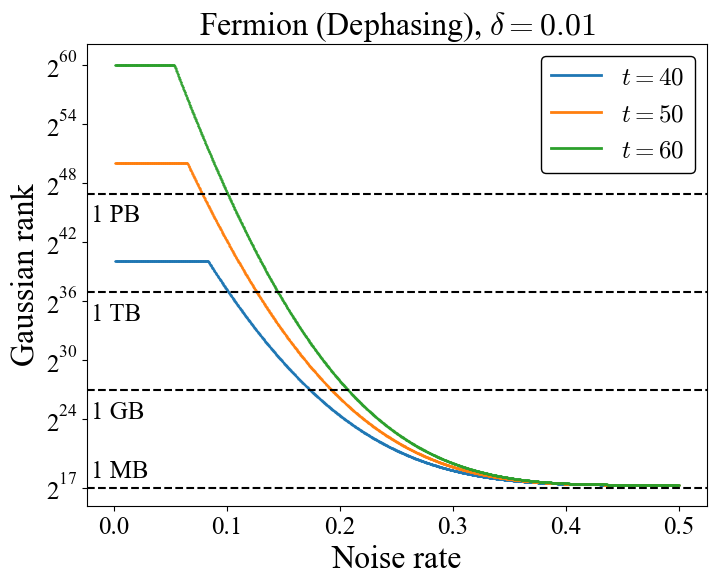

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

delta = 0.01
t1, t2, t3 = 40, 50, 60

p = np.linspace(0.001, 0.5, 2000)

y1 = []
y2 = []
y3 = []
for i in range(len(p)):
    y1.append(final_rank(t1, nu2(p[i]), delta))
    y2.append(final_rank(t2, nu2(p[i]), delta))
    y3.append(final_rank(t3, nu2(p[i]), delta))


plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']
plt.rcParams['mathtext.fontset'] = 'cm'

plt.figure(figsize=(8, 6))


ln1 = plt.plot(p, y1, linestyle='None', marker='.', markersize=1)[0]
ln2 = plt.plot(p, y2, linestyle='None', marker='.', markersize=1)[0]
ln3 = plt.plot(p, y3, linestyle='None', marker='.', markersize=1)[0]

plt.xlabel('Noise rate', fontsize=23)
plt.ylabel('Gaussian rank', fontsize=23)
plt.yscale('log', base=2)


plt.axhline(MB, linestyle='--', color='k')
plt.text(-0.02, 2**18, '1 MB', fontsize=18)

plt.axhline(GB, linestyle='--', color='k')
plt.text(-0.02, 2**24, '1 GB', fontsize=18)

plt.axhline(TB, linestyle='--', color='k')
plt.text(-0.02, 2**34, '1 TB', fontsize=18)

plt.axhline(PB, linestyle='--', color='k')
plt.text(-0.02, 2**44, '1 PB', fontsize=18)


colors = [ln1.get_color(), ln2.get_color(), ln3.get_color()]

proxy_handles = [
    Line2D([0], [0], color=colors[0], lw=2),
    Line2D([0], [0], color=colors[1], lw=2),
    Line2D([0], [0], color=colors[2], lw=2),
]
proxy_labels = [r'$t=40$', r'$t=50$', r'$t=60$']

plt.legend(proxy_handles, proxy_labels,
           fontsize=18,
           framealpha=1.0,
           edgecolor='k',
           handlelength=2.0)

plt.xticks(fontsize=18)
plt.yticks([2**17, 2**24, 2**30, 2**36, 2**42, 2**48, 2**54, 2**60],fontsize=18)

plt.title('Fermion (Dephasing), $\delta=0.01$', fontsize=23)
plt.savefig('Fermion(Dephasing)', dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.show()
